## Name : Chandru M
## Reg NO : 212224230041

In [2]:
# Import libraries
import cv2
import numpy as np
import matplotlib.pyplot as plt

Text(0.5, 1.0, 'Face')

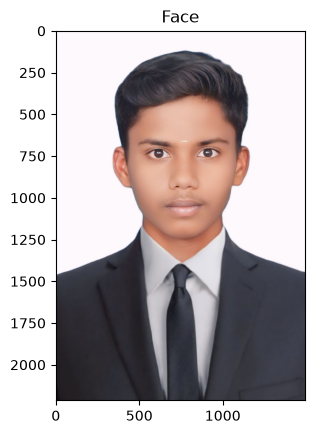

In [3]:
# Load the Face Image
faceImage = cv2.imread(r"E:\College\THIRD YEAR\5TH SEM\DIPT\chandru.jpg")
plt.imshow(faceImage[:,:,::-1]);plt.title("Face")


In [4]:
faceImage.shape

(2214, 1491, 3)

In [5]:
#resized_faceImage.shape
faceImage.shape

(2214, 1491, 3)

Text(0.5, 1.0, 'glassPNG')

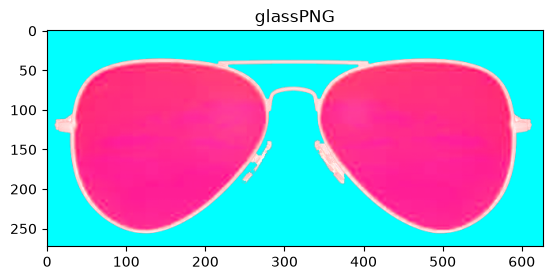

In [6]:
# Load the Sunglass image with Alpha channel
# (http://pluspng.com/sunglass-png-1104.html)
glassPNG = cv2.imread(r"E:\College\THIRD YEAR\5TH SEM\DIPT\glass.png",-1)
plt.imshow(glassPNG[:,:,::-1]);plt.title("glassPNG")

In [7]:
# Resize the image to fit over the eye region
glassPNG = cv2.resize(glassPNG,(190,50))
print("image Dimension ={}".format(glassPNG.shape))

image Dimension =(50, 190, 4)


In [8]:
# Separate the Color and alpha channels
glassBGR = glassPNG[:,:,0:3]
glassMask1 = glassPNG[:,:,3]

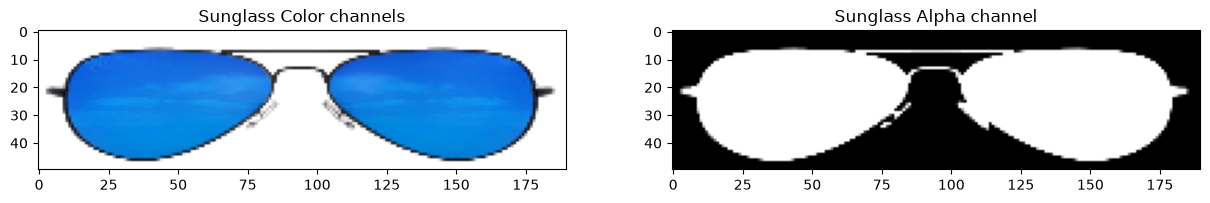

In [9]:
# Display the images for clarity
plt.figure(figsize=[15,15])
plt.subplot(121);plt.imshow(glassBGR[:,:,::-1]);plt.title('Sunglass Color channels');
plt.subplot(122);plt.imshow(glassMask1,cmap='gray');plt.title('Sunglass Alpha channel');

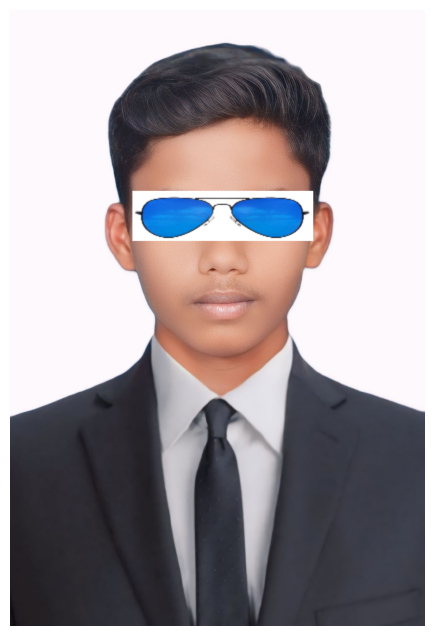

In [19]:
# Make a copy
faceWithGlassesNaive = faceImage.copy()

# Resize the sunglasses (width=190, height=50)
glassResized = cv2.resize(glassBGR, (650, 180))

# Place the sunglasses over the eyes
faceWithGlassesNaive[650:830, 440:1090] = glassResized

# Display the result
plt.figure(figsize=(6, 8))
plt.imshow(faceWithGlassesNaive[..., ::-1])
plt.axis('off')
plt.show()

Text(0.5, 1.0, 'Augmented Eye and Sunglass')

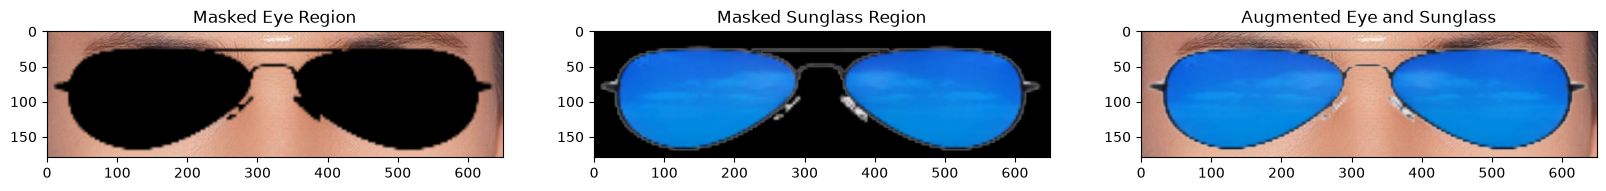

In [21]:
# Make the dimensions of the mask same as the input image
glassMask = cv2.merge((glassMask1, glassMask1, glassMask1))

# Make the values [0,1]
glassMask = np.float32(glassMask / 255.0)

# Resize the sunglasses and mask to match the eye region
glassBGR = cv2.resize(glassBGR, (650, 180))
glassMask = cv2.resize(glassMask, (650, 180))

# Make a copy
faceWithGlassesArithmetic = faceImage.copy()

# Get the eye region from the face image
eyeROI = faceWithGlassesArithmetic[650:830, 440:1090]

# Create the masked eye region
maskedEye = cv2.multiply(eyeROI.astype(np.float32), 1 - glassMask)

# Create the masked sunglass region
maskedGlass = cv2.multiply(glassBGR.astype(np.float32) / 255.0, glassMask)

# Combine the sunglasses with the eye region
eyeRoiFinal = cv2.add(maskedEye / 255.0, maskedGlass)

# Convert to uint8
eyeRoiFinal = np.uint8(np.clip(eyeRoiFinal * 255, 0, 255))

# Display the intermediate results
plt.figure(figsize=[20,20])
plt.subplot(131)
plt.imshow(maskedEye.astype(np.uint8)[...,::-1])
plt.title("Masked Eye Region")

plt.subplot(132)
plt.imshow((maskedGlass * 255).astype(np.uint8)[...,::-1])
plt.title("Masked Sunglass Region")

plt.subplot(133)
plt.imshow(eyeRoiFinal[...,::-1])
plt.title("Augmented Eye and Sunglass")

Text(0.5, 1.0, 'With Sunglasses')

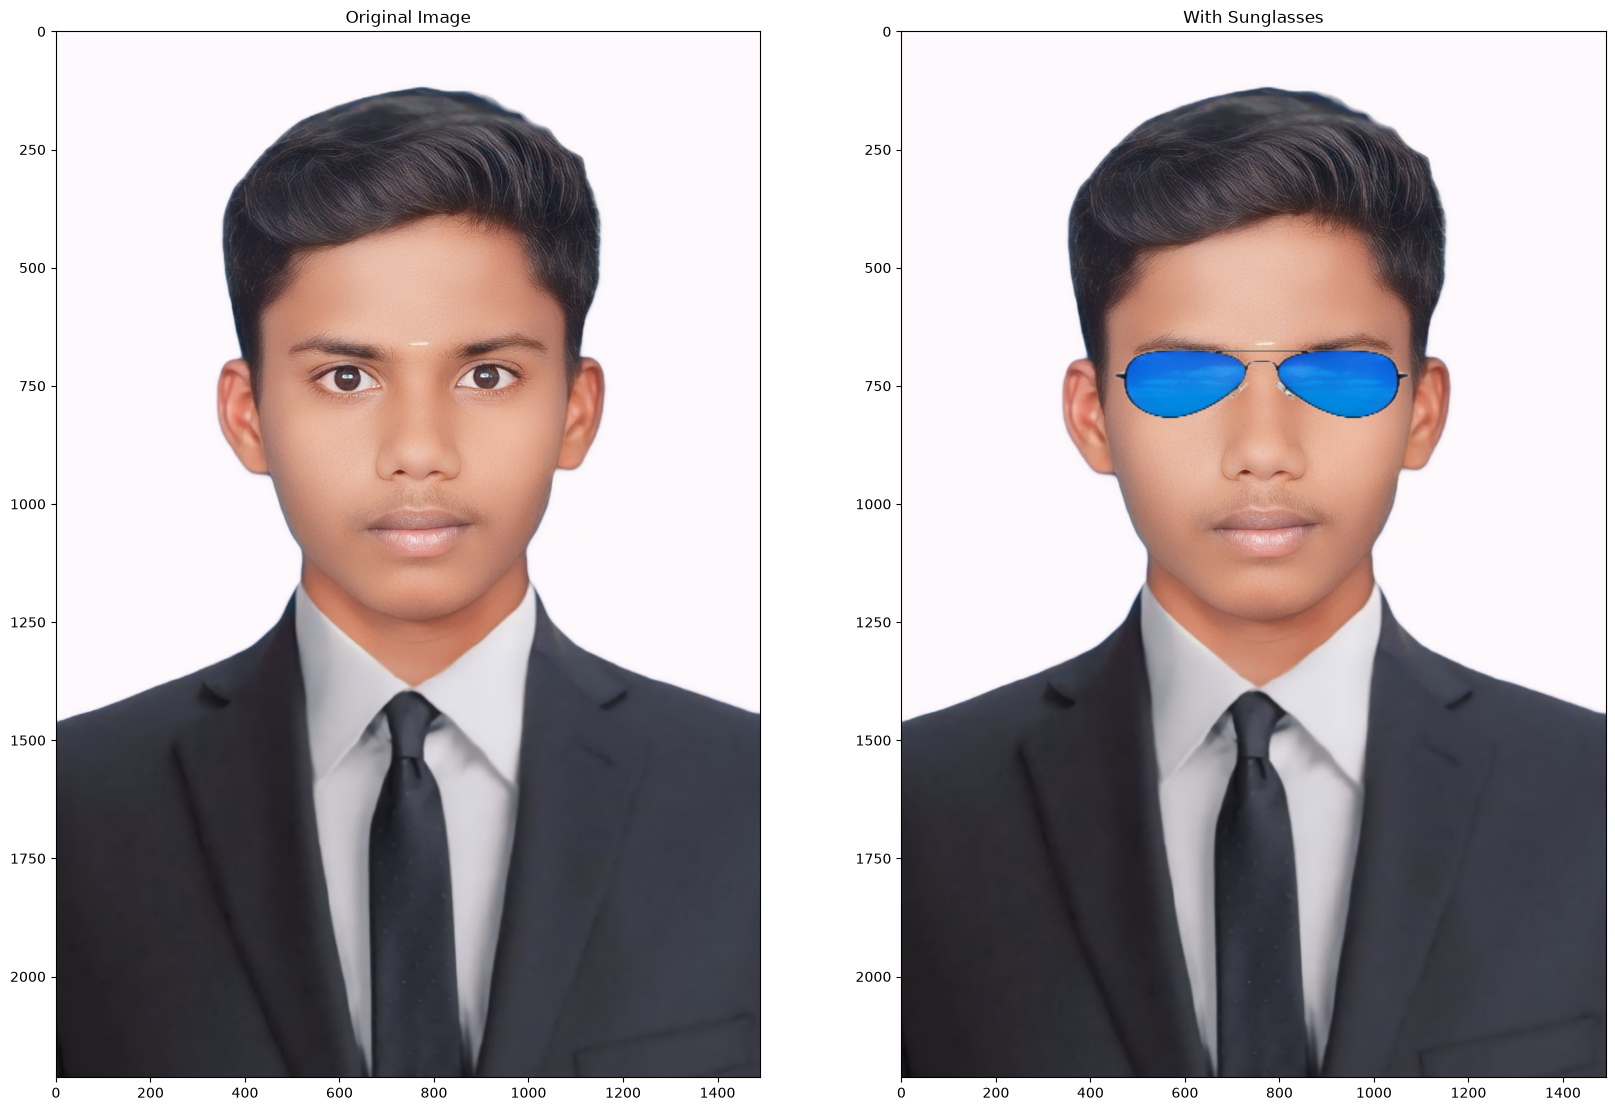

In [22]:
# Replace the eye ROI with the output from the previous section
faceWithGlassesArithmetic[650:830, 440:1090] = eyeRoiFinal

# Display the final result
plt.figure(figsize=[20,20])
plt.subplot(121)
plt.imshow(faceImage[:,:,::-1])
plt.title("Original Image")

plt.subplot(122)
plt.imshow(faceWithGlassesArithmetic[:,:,::-1])
plt.title("With Sunglasses")